# TP : SVM
## Objectifs
- Implémenter des SVM linéaires et non linéaires
- Tester différents noyaux et paramètres (C, gamma…)
- Visualiser les frontières de décision
- Comprendre l’impact des hyperparamètres
- Introduire l’astuce du noyau

## Consignes
Les cellules contenant `TODO` doivent être complétées.


In [6]:
# TODO : importer les bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_moons
from matplotlib.colors import ListedColormap


In [7]:

def plot_decision_boundary_with_margins(clf, X, y, h=0.02, title="Decision Boundary"):
     #--- Diagram colormap ---
     cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF'])
     cmap_bold = ListedColormap(['#FF0000', '#0000FF'])

     #--- Create mesh grid ---
     x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
     y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1

     xx, yy = np.meshgrid(
         np.arange(x_min, x_max, h),
         np.arange(y_min, y_max, h)
     )
     grid = np.c_[xx.ravel(), yy.ravel()]

     #--- Predict on grid ---
     Z = clf.predict(grid).reshape(xx.shape)
     plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)

    #--- Decision function (for margins & boundaries) ---
     if hasattr(clf, "decision_function"):
         df = clf.decision_function(grid).reshape(xx.shape)

         # Decision boundary (df = 0)
         plt.contour(xx, yy, df, levels=[0], colors='k', linewidths=2)

         # Margins (df = ±1)
         plt.contour(xx, yy, df, levels=[-1, 1],
                      colors='k', linestyles='--', linewidths=1.4)

     #--- Plot points ---
     plt.scatter(X[:,0], X[:,1], c=y, cmap=cmap_bold, s=30, edgecolors='k')

     #--- Plot support vectors ---
     if hasattr(clf, "support_vectors_"):
         plt.scatter(
             clf.support_vectors_[:,0],
             clf.support_vectors_[:,1],
             s=120, linewidth=1,
             facecolors='none', edgecolors='yellow',
             label='Support Vectors'
         )

     plt.title(title)
     plt.xlabel("Feature 1")
     plt.ylabel("Feature 2")
     plt.legend()
     plt.show()


## PARTIE 1 — Classification SVM Linéaire sur Iris
### Chargement du dataset Iris

In [8]:
# TODO : Charger le dataset Iris
iris = datasets.load_iris()

# Pour simplifier le problème : classification binaire
# TODO : sélectionner uniquement deux classes, par exemple 1 et 2
X = iris.data[:, 2:4]     # On garde uniquement Petal length & width
y = iris.target

# TODO : filtrage binaire Versicolor (1) vs Virginica (2)

# TODO : train/test split
mask = y != 0
X = X[mask]
y = y[mask]

X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.3, random_state=0
)


----- Test avec C = 1 -----
Accuracy train : 0.9428571428571428
Accuracy test  : 0.9666666666666667


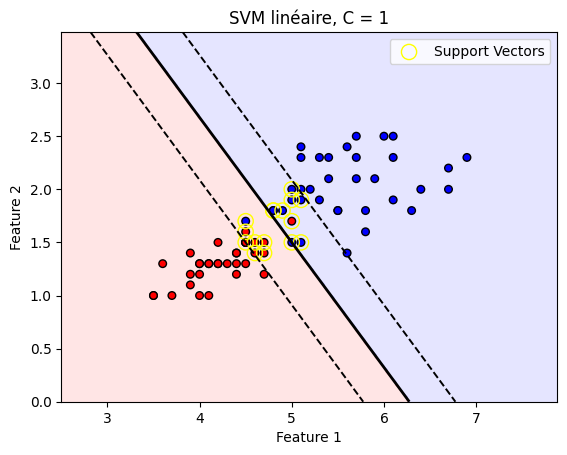

----- Test avec C = 100 -----
Accuracy train : 0.9571428571428572
Accuracy test  : 0.9


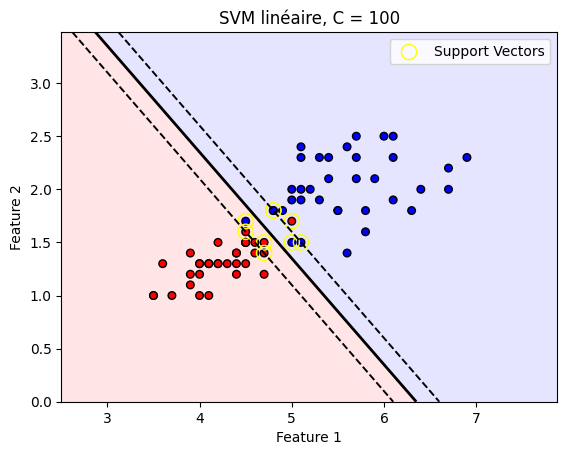

In [9]:
# TODO : entraîner deux modèles linéaires pour C = 1 et C = 100
for C in [1, 100]:
     print("----- Test avec C =", C, "-----")
     model = SVC(kernel='linear', C=C)
     model.fit(X_train, y_train)
     print("Accuracy train :", model.score(X_train, y_train))
     print("Accuracy test  :", model.score(X_test, y_test))
     plt.figure()
     plot_decision_boundary_with_margins(model, X_train, y_train, title=f"SVM linéaire, C = {C}")
     # TODO : entraîner modèle
     # TODO : afficher accuracy
     # TODO : afficher frontière de décision


## PARTIE 2 — Classification SVM Non Linéaire
### Génération du dataset Moons

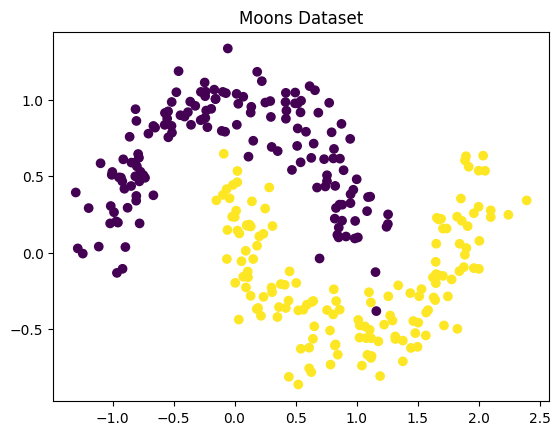

In [10]:
# TODO : Générer données non linéaires
X_moons, y_moons = make_moons(n_samples=300, noise=0.15, random_state=0)

# TODO : afficher les points
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons)
plt.title("Moons Dataset")
plt.show()

### SVM Non Linéaire (RBF)


Accuracy train (RBF) : 0.9761904761904762
Accuracy test  (RBF) : 1.0


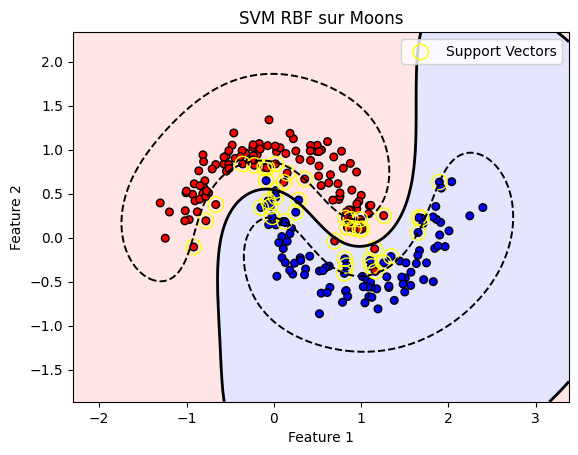

In [13]:
# TODO : entraîner un SVM non linéaire avec kernel RBF
model_rbf = SVC(kernel='rbf', gamma='scale')
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.3, random_state=0
)
model_rbf.fit(X_moons_train, y_moons_train)
print("Accuracy train (RBF) :", model_rbf.score(X_moons_train, y_moons_train))
print("Accuracy test  (RBF) :", model_rbf.score(X_moons_test, y_moons_test))
plot_decision_boundary_with_margins(model_rbf, X_moons_train, y_moons_train,
title="SVM RBF sur Moons")
              
# TODO : fit model
# TODO : afficher accuracy
# TODO : afficher frontière de décision


### Tester la classification par un SVM linéaire sur le dataset Moons

Accuracy train (linéaire) : 0.8476190476190476
Accuracy test  (linéaire) : 0.8555555555555555


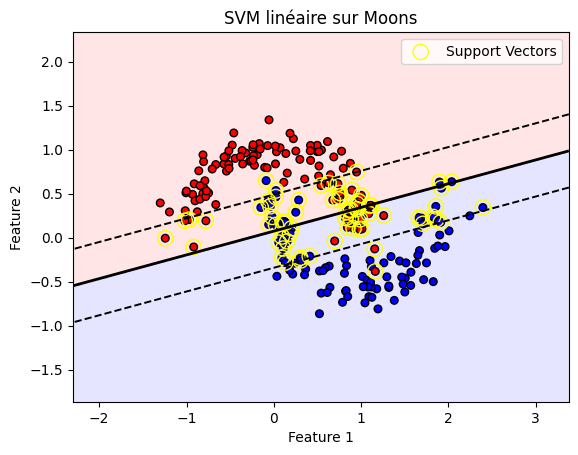

In [14]:
# TODO : créer modèle
model_lin_moons = SVC(kernel='linear', C=1)

# TODO : entraîner modèle
model_lin_moons.fit(X_moons_train, y_moons_train)

# TODO : afficher accuracy
print("Accuracy train (linéaire) :", model_lin_moons.score(X_moons_train, y_moons_train))
print("Accuracy test  (linéaire) :", model_lin_moons.score(X_moons_test, y_moons_test))

# TODO : afficher frontière de décision
plot_decision_boundary_with_margins(model_lin_moons, X_moons_train, y_moons_train,
                                    title="SVM linéaire sur Moons")

## PARTIE 3 — Astuce du noyau
### Test d’autres noyaux

In [ ]:
kernels = ['poly', 'rbf', 'sigmoid']

for k in kernels:
     print("----- Kernel =", k, "-----")
     # TODO : créer et entraîner un SVM avec ce noyau
     # TODO : afficher la frontière de décision


## PARTIE 4 — Questions théoriques


## Questions théoriques

1. Pourquoi un SVM linéaire échoue-t-il sur des données non linéaires ?
2. Quel est le rôle du paramètre **C** dans un SVM ?
3. Quel est le rôle du paramètre **gamma** dans le SVM RBF ?
4. Expliquer l'intérêt de l’astuce du noyau.
5. Pourquoi les SVM sont-ils sensibles à l’échelle des données ?
6. Dans quel cas choisir un SVM linéaire plutôt qu'un SVM à noyau ?
